In [63]:
import os
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray as xr
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import netCDF4
import h5netcdf
import dask
from dask.diagnostics import ProgressBar
import rasterio.features as features
import glob
from netCDF4 import Dataset
from shapely.geometry import box

In [64]:
path_t2_data = "/scratch/mpekkala/Transmissivity_maps/1998_2002_transmissivity_data/t2_*.nc"

In [65]:
path_ENVEO_transmissivity = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/20200710_CANOPY_CORRECTION_LAYER_TCD_LCCCI_2000_v01_005deg.tif'

In [66]:
path_ENVEO_icemask = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/icemask50.tif'

In [67]:
path_ENVEO_watermask = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/watermask50.tif'

In [68]:
path_map = '/scratch/mpekkala/Transmissivity_maps/World_Continents/World_Continents.shp'

In [69]:
Map = gpd.read_file(path_map)

In [70]:
ENVEO = rioxarray.open_rasterio(path_ENVEO_transmissivity)

In [71]:
ENVEO_ice = rioxarray.open_rasterio(path_ENVEO_icemask)

In [72]:
ENVEO_water = rioxarray.open_rasterio(path_ENVEO_watermask)

In [73]:
years = [1998, 1999, 2000, 2001, 2002]

In [74]:
ds_t2 = xr.open_mfdataset(
    files,                  # the sorted list from earlier, not path_t2_data
    combine="nested",
    concat_dim="year",      # a name (string), not a pd.Index
)
ds_t2 = ds_t2.assign_coords(year=years)

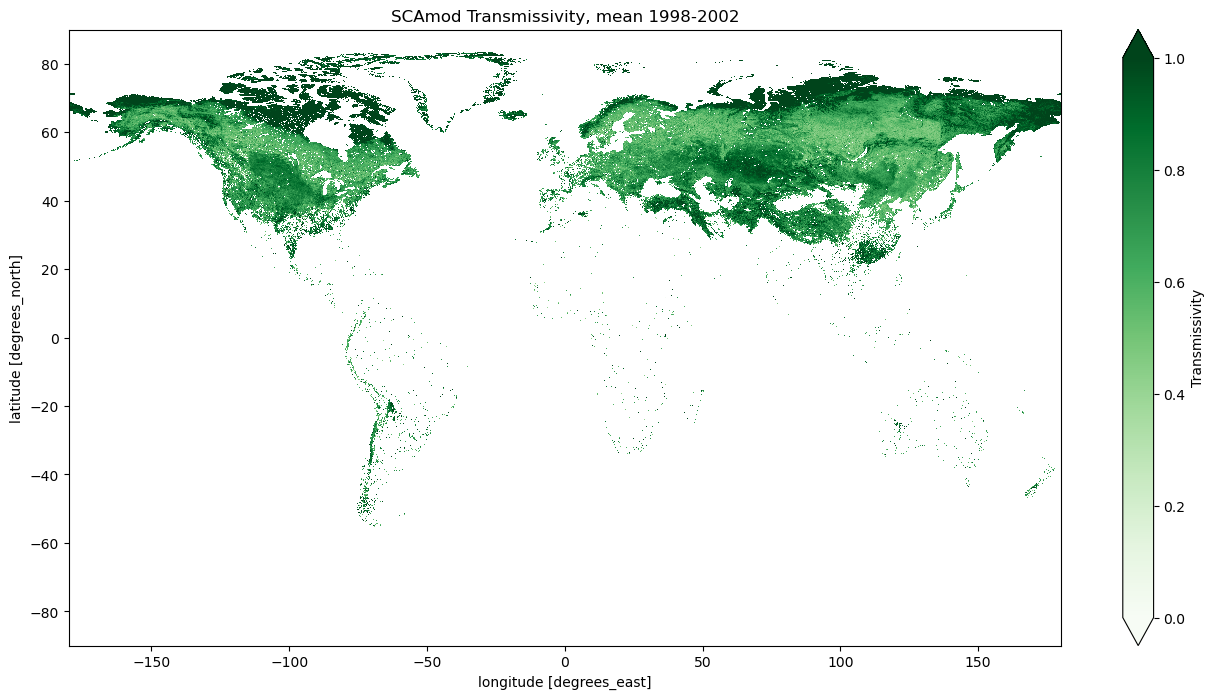

In [75]:
t2 = ds_t2["__xarray_dataarray_variable__"]

t2_mean = t2.mean(dim="year", skipna=True)     # 2D map: mean of all years

fig, ax = plt.subplots(figsize=(16, 8))

t2_mean.plot(
    ax=ax,
    cmap="Greens",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Transmissivity"},
)

ax.set_title("SCAmod Transmissivity, mean 1998-2002")

os.makedirs("Figures", exist_ok=True)
fig.savefig(
    "Figures/SCAmod_transmissivity_mean_1998_2002.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

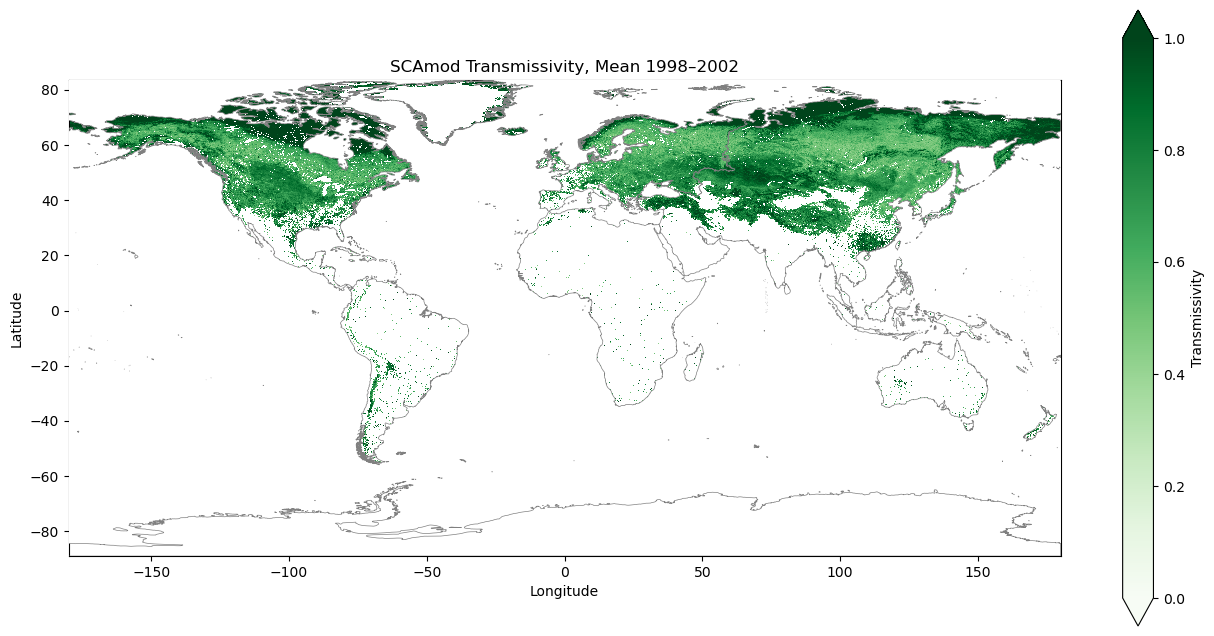

In [102]:
import os
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box

# Convert map to EPSG:4326
Map = Map.to_crs(epsg=4326)

# SCAmod: mean over all years
t2 = ds_t2["__xarray_dataarray_variable__"]
t2_mean = t2.mean(dim="year", skipna=True)

# Create figure
fig, ax = plt.subplots(figsize=(16, 8))

# Plot SCAmod transmissivity
t2_mean.plot(
    ax=ax,
    cmap="Greens",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Transmissivity"},
    zorder=1,
)

# Get map extent
xmin, ymin, xmax, ymax = Map.total_bounds

# Create background rectangle
background = gpd.GeoDataFrame(
    geometry=[box(xmin, ymin, xmax, ymax)],
    crs="EPSG:4326",
)

# Identify areas outside Map
outside = gpd.overlay(
    background,
    Map[["geometry"]],
    how="difference",
)

# Paint areas outside Map white
outside.plot(
    ax=ax,
    color="white",
    edgecolor="none",
    zorder=3,
)

# Plot map boundaries with transparent fill and grey edges
Map.plot(
    ax=ax,
    facecolor="none",
    edgecolor="grey",
    linewidth=0.5,
    zorder=4,
)

# Set map extent
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Title and axis labels
ax.set_title("SCAmod Transmissivity, Mean 1998–2002")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# Save figure
os.makedirs("Figures", exist_ok=True)

fig.savefig(
    "Figures/SCAmod_transmissivity_mean_1998_2002.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

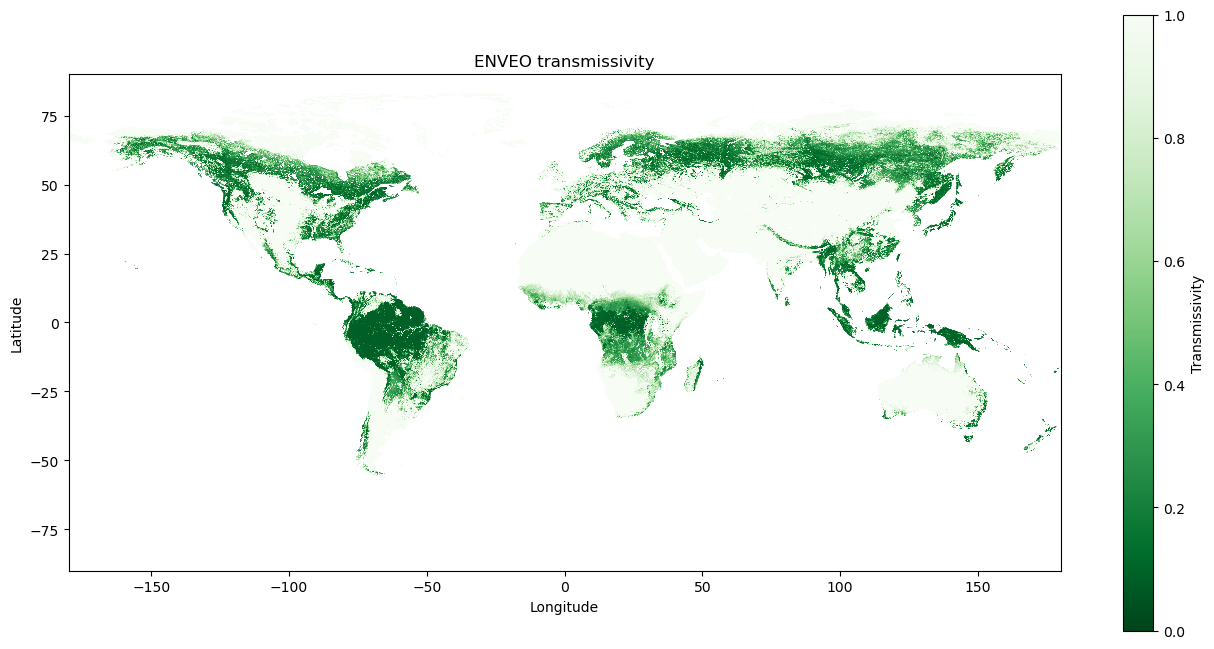

In [96]:
# Convert map to EPSG:4326
Map = Map.to_crs(epsg=4326)

# Reversed colormap with NaNs rendered white
cmap = plt.cm.Greens_r.copy()
cmap.set_bad(color="white")

# Combine all mask layers into one boolean mask
combined_mask = (
    (ENVEO_ice == 0) |
    (ENVEO_water == 0)
)

# Apply mask: set flagged pixels to NaN so they render white via cmap.set_bad
ENVEO_masked = ENVEO.where(~combined_mask)

# Create rectangular figure
fig, ax = pyplot.subplots(figsize=(16, 8))

# Plot ENVEO transmissivity (masked)
ENVEO_masked.plot(
    ax=ax,
    cmap=cmap,
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Transmissivity"}
)

# Get the extent of the map
xmin, ymin, xmax, ymax = Map.total_bounds

# Create a rectangle covering the whole plotting area
background = gpd.GeoDataFrame(
    geometry=[box(xmin, ymin, xmax, ymax)],
    crs="EPSG:4326"
)

# Create the areas OUTSIDE Map
outside = gpd.overlay(
    background,
    Map[["geometry"]],
    how="difference"
)

# Paint only the outside areas white
outside.plot(
    ax=ax,
    color="white",
    edgecolor="none"
)


# Labels and title
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
pyplot.title("ENVEO transmissivity")

# Save figure
pyplot.savefig(
    "Figures/enveo_transmissivity.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

pyplot.show()

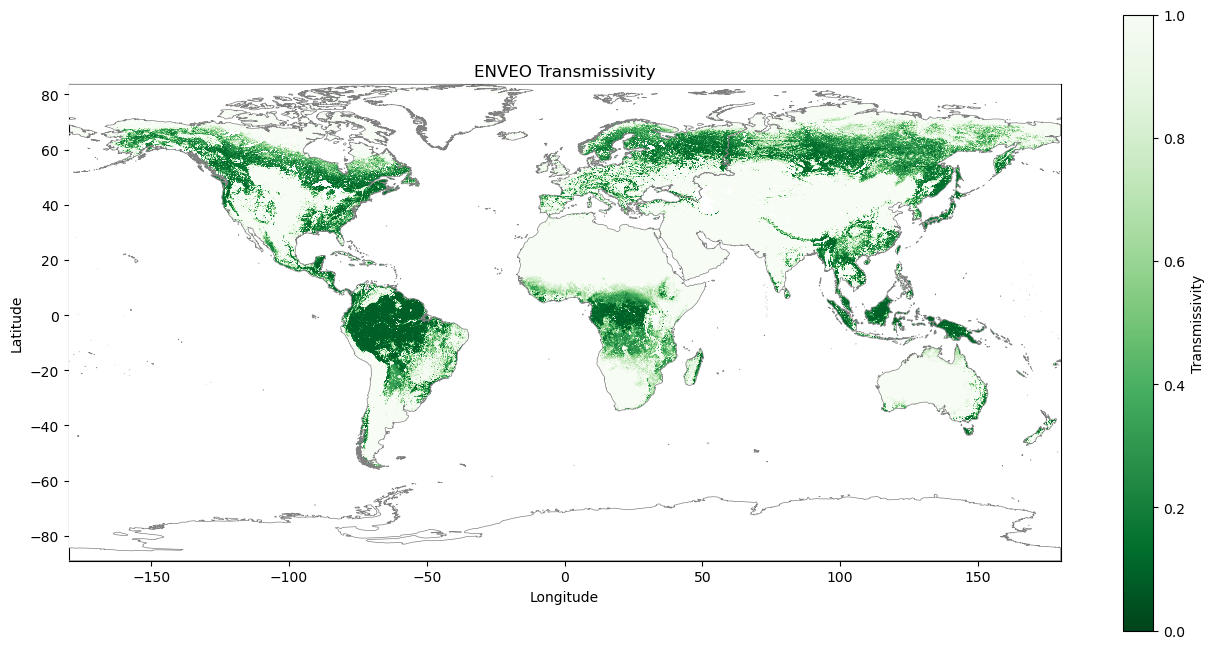

In [101]:
import os
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box

# Create output directory
os.makedirs("Figures", exist_ok=True)

# Convert map to EPSG:4326
Map = Map.to_crs(epsg=4326)

# Reversed colormap with NaNs rendered white
cmap = plt.cm.Greens_r.copy()
cmap.set_bad(color="white")

# Combine all mask layers into one boolean mask
combined_mask = (
    (ENVEO_ice == 0) |
    (ENVEO_water == 0)
)

# Apply mask
ENVEO_masked = ENVEO.where(~combined_mask)

# Create rectangular figure
fig, ax = plt.subplots(figsize=(16, 8))

# Plot ENVEO transmissivity
ENVEO_masked.plot(
    ax=ax,
    cmap=cmap,
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Transmissivity"}
)

# Get map extent
xmin, ymin, xmax, ymax = Map.total_bounds

# Create a rectangle covering the plotting area
background = gpd.GeoDataFrame(
    geometry=[box(xmin, ymin, xmax, ymax)],
    crs="EPSG:4326"
)

# Create areas outside Map
outside = gpd.overlay(
    background,
    Map[["geometry"]],
    how="difference"
)

# Paint areas outside Map white
outside.plot(
    ax=ax,
    color="white",
    edgecolor="none",
    zorder=3
)

# Plot map boundaries with transparent fill and black borders
Map.plot(
    ax=ax,
    facecolor="none",
    edgecolor="grey",
    linewidth=0.5,
    zorder=4
)

# Set map extent
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Labels and title
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("ENVEO Transmissivity")

# Save figure
plt.savefig(
    "Figures/enveo_transmissivity.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

ENVEO mid  : valid px: 2224211
SCAmod S   : valid px: 22824
SCAmod N   : valid px: 2943574


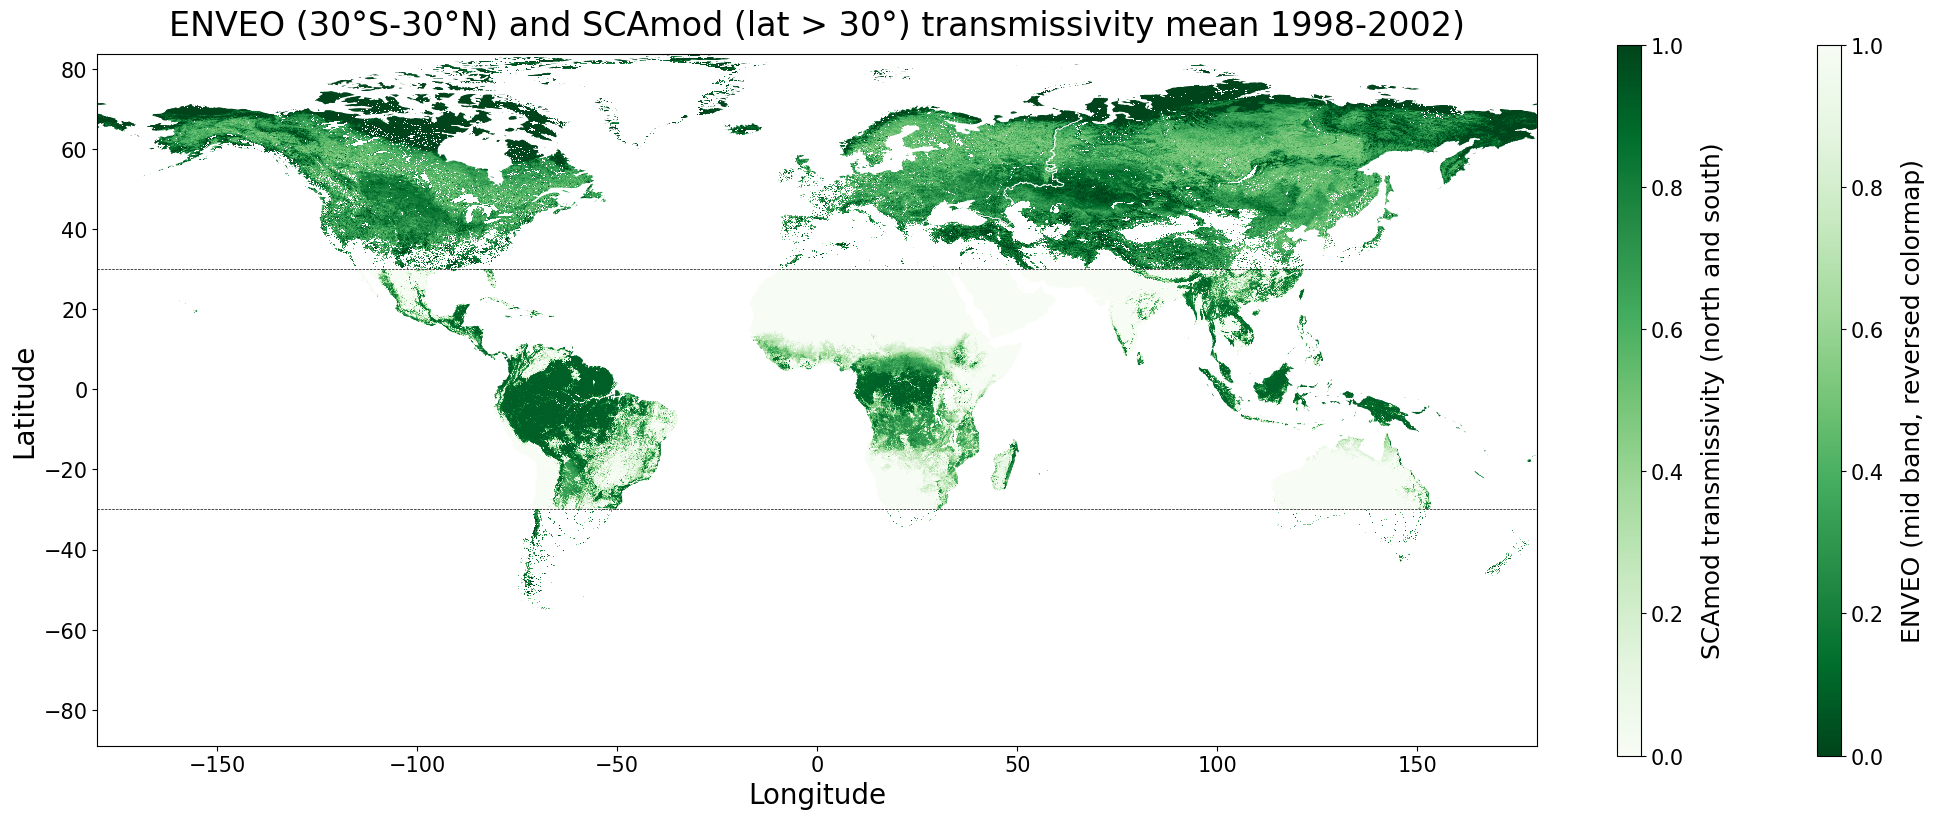

In [61]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box

# ------------------------------------------------------------------
# Settings
# ------------------------------------------------------------------
LAT_MIN, LAT_MAX = -30, 30      # ENVEO inside, SCAmod poleward of this band
os.makedirs("Figures", exist_ok=True)

# Font sizes
FS_TITLE = 24     # figure title
FS_LABEL = 20     # x/y axis labels
FS_CBAR  = 18     # colorbar titles
FS_TICK  = 15     # tick labels (axes and colorbars)

# ------------------------------------------------------------------
# Helper: standardise coordinate names, longitude convention and ordering
# ------------------------------------------------------------------
def std_latlon(da):
    cand = {"y": "lat", "x": "lon",
            "latitude": "lat", "longitude": "lon",
            "Latitude": "lat", "Longitude": "lon",
            "Lat": "lat", "Lon": "lon"}
    rename = {k: v for k, v in cand.items() if (k in da.dims or k in da.coords)}
    da = da.rename(rename)
    da = da.assign_coords(lon=((da.lon + 180) % 360) - 180)
    da = da.sortby("lon").sortby("lat")
    return da

# ------------------------------------------------------------------
# 1. SCAmod: mean over years (native grid)
# ------------------------------------------------------------------
t2 = ds_t2["__xarray_dataarray_variable__"]
t2_mean = std_latlon(t2.mean(dim="year", skipna=True).squeeze())

# ------------------------------------------------------------------
# 2. ENVEO: standardise and apply ice/water mask (values NOT inverted)
# ------------------------------------------------------------------
ENVEO       = std_latlon(ENVEO.squeeze())
ENVEO_ice   = std_latlon(ENVEO_ice.squeeze())
ENVEO_water = std_latlon(ENVEO_water.squeeze())

combined_mask = (ENVEO_ice == 0) | (ENVEO_water == 0)
ENVEO_masked = ENVEO.where(~combined_mask)

# ------------------------------------------------------------------
# 3. Disjoint latitude subsets (no pixel belongs to both products)
# ------------------------------------------------------------------
enveo_mid    = ENVEO_masked.where((ENVEO_masked.lat >= LAT_MIN) &
                                  (ENVEO_masked.lat <= LAT_MAX), drop=True)
scamod_south = t2_mean.where(t2_mean.lat < LAT_MIN, drop=True)
scamod_north = t2_mean.where(t2_mean.lat > LAT_MAX, drop=True)

print("ENVEO mid  : valid px:", int(enveo_mid.notnull().sum()))
print("SCAmod S   : valid px:", int(scamod_south.notnull().sum()))
print("SCAmod N   : valid px:", int(scamod_north.notnull().sum()))

# ------------------------------------------------------------------
# 4. Colormaps
# ------------------------------------------------------------------
cmap_scamod = plt.cm.Greens.copy()
cmap_scamod.set_bad("white")

cmap_enveo = plt.cm.Greens_r.copy()     # inverted colormap for ENVEO
cmap_enveo.set_bad("white")

# ------------------------------------------------------------------
# 5. Figure with explicit axes: map + two colorbar axes with fixed spacing
#    [left, bottom, width, height] in figure fractions
# ------------------------------------------------------------------
Map = Map.to_crs(epsg=4326)

fig = plt.figure(figsize=(20, 9))
ax         = fig.add_axes([0.06, 0.11, 0.72, 0.79])    # map
cax_scamod = fig.add_axes([0.82, 0.11, 0.012, 0.79])   # SCAmod colorbar
cax_enveo  = fig.add_axes([0.92, 0.11, 0.012, 0.79])   # ENVEO colorbar

kw_s = dict(ax=ax, cmap=cmap_scamod, vmin=0, vmax=1, add_colorbar=False)
mesh_scamod = scamod_south.plot(**kw_s)
scamod_north.plot(**kw_s)

mesh_enveo = enveo_mid.plot(ax=ax, cmap=cmap_enveo, vmin=0, vmax=1,
                            add_colorbar=False)

# White mask outside the Map polygon(s)
xmin, ymin, xmax, ymax = Map.total_bounds
background = gpd.GeoDataFrame(geometry=[box(xmin, ymin, xmax, ymax)], crs="EPSG:4326")
outside = gpd.overlay(background, Map[["geometry"]], how="difference")
outside.plot(ax=ax, color="white", edgecolor="none")

# Map boundaries
Map.plot(ax=ax, facecolor="none", edgecolor="white", linewidth=0.5)

# Product boundaries
ax.axhline(LAT_MIN, color="k", lw=0.5, ls="--")
ax.axhline(LAT_MAX, color="k", lw=0.5, ls="--")

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Colorbars in their own axes
cbar_scamod = fig.colorbar(mesh_scamod, cax=cax_scamod)
cbar_scamod.set_label("SCAmod transmissivity (north and south)",
                      fontsize=FS_CBAR, labelpad=12)
cbar_scamod.ax.tick_params(labelsize=FS_TICK)

cbar_enveo = fig.colorbar(mesh_enveo, cax=cax_enveo)
cbar_enveo.set_label("ENVEO (mid band, reversed colormap)",
                     fontsize=FS_CBAR, labelpad=12)
cbar_enveo.ax.tick_params(labelsize=FS_TICK)

# Axis labels, tick labels and title
ax.set_xlabel("Longitude", fontsize=FS_LABEL)
ax.set_ylabel("Latitude", fontsize=FS_LABEL)
ax.tick_params(axis="both", labelsize=FS_TICK)
ax.set_title("ENVEO (30°S-30°N) and SCAmod (lat > 30°) transmissivity mean 1998-2002)",
             fontsize=FS_TITLE, pad=14)

fig.savefig(
    "Figures/enveo_scamod_merged_transmissivity.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

ENVEO mid: valid pixels: 2224211
SCAmod S : valid pixels: 22824
SCAmod N : valid pixels: 2943574


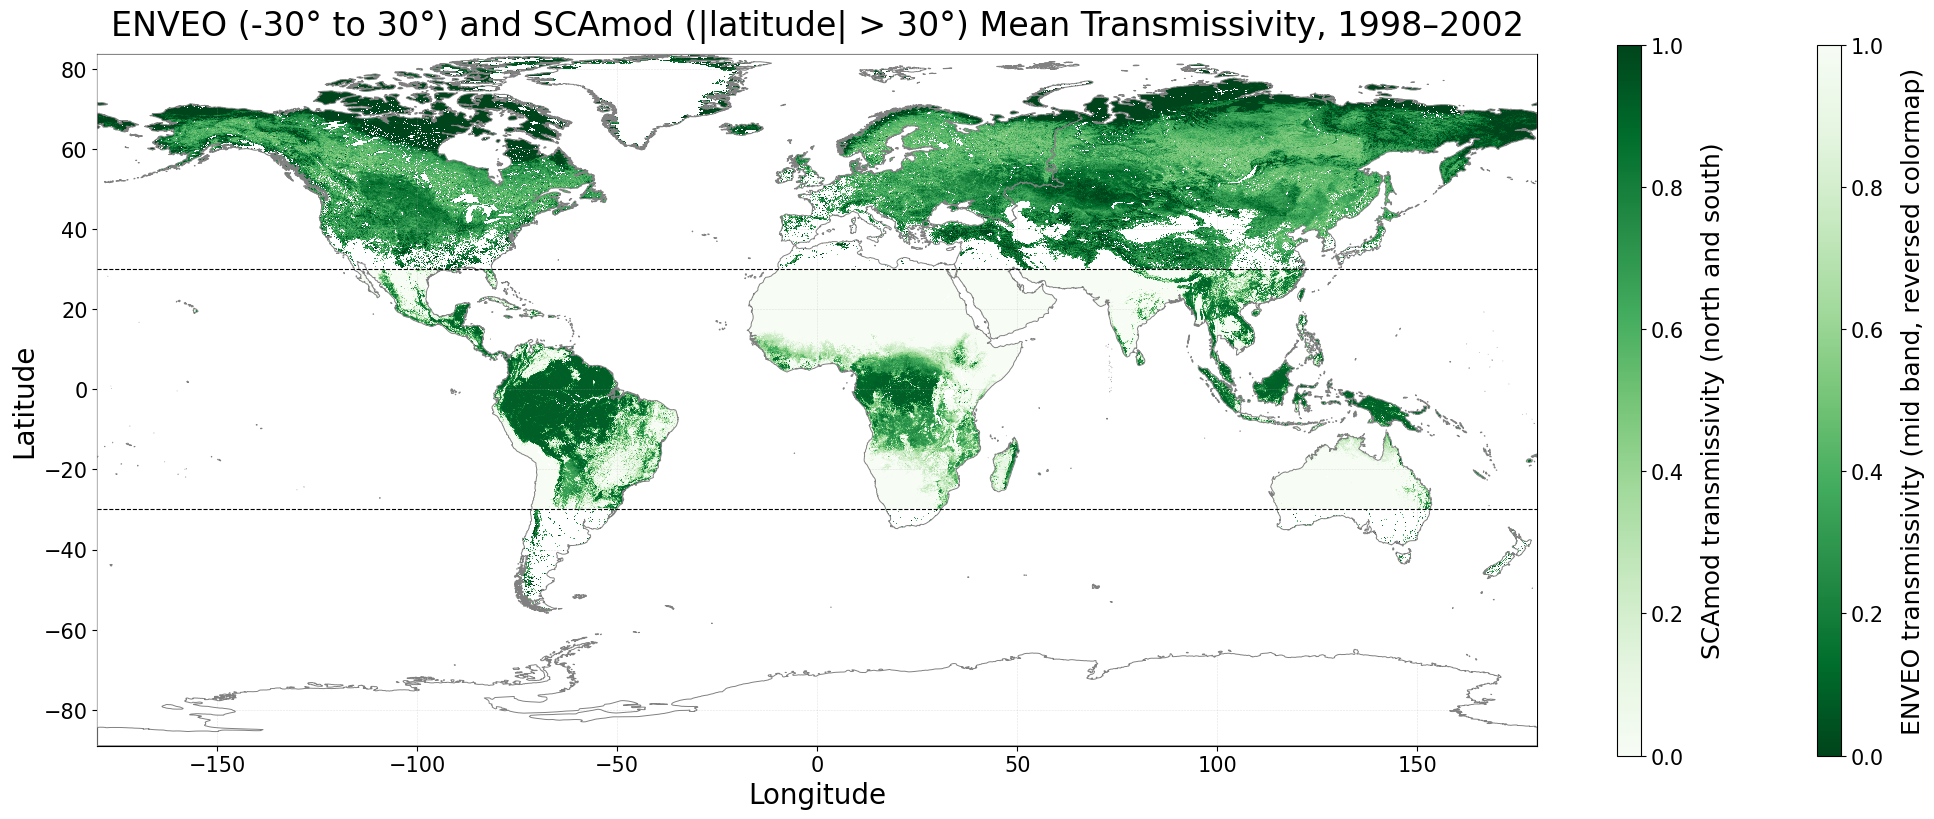

In [99]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box

# ------------------------------------------------------------------
# Settings
# ------------------------------------------------------------------
LAT_MIN, LAT_MAX = -30, 30

os.makedirs("Figures", exist_ok=True)

# Font sizes
FS_TITLE = 24
FS_LABEL = 20
FS_CBAR  = 18
FS_TICK  = 15

# ------------------------------------------------------------------
# Helper: standardise coordinate names, longitude convention and ordering
# ------------------------------------------------------------------
def std_latlon(da):
    cand = {
        "y": "lat",
        "x": "lon",
        "latitude": "lat",
        "longitude": "lon",
        "Latitude": "lat",
        "Longitude": "lon",
        "Lat": "lat",
        "Lon": "lon",
    }

    rename = {
        k: v for k, v in cand.items()
        if k in da.dims or k in da.coords
    }

    da = da.rename(rename)
    da = da.assign_coords(lon=((da.lon + 180) % 360) - 180)
    da = da.sortby("lon").sortby("lat")

    return da


# ------------------------------------------------------------------
# 1. SCAmod: mean over years
# ------------------------------------------------------------------
t2 = ds_t2["__xarray_dataarray_variable__"]

t2_mean = std_latlon(
    t2.mean(dim="year", skipna=True).squeeze()
)


# ------------------------------------------------------------------
# 2. ENVEO: standardise and apply ice/water mask
# ------------------------------------------------------------------
ENVEO = std_latlon(ENVEO.squeeze())
ENVEO_ice = std_latlon(ENVEO_ice.squeeze())
ENVEO_water = std_latlon(ENVEO_water.squeeze())

combined_mask = (ENVEO_ice == 0) | (ENVEO_water == 0)
ENVEO_masked = ENVEO.where(~combined_mask)


# ------------------------------------------------------------------
# 3. Disjoint latitude subsets
#    ENVEO: -30 to +30 degrees
#    SCAmod: south of -30 and north of +30 degrees
# ------------------------------------------------------------------
enveo_mid = ENVEO_masked.where(
    (ENVEO_masked.lat >= LAT_MIN) &
    (ENVEO_masked.lat <= LAT_MAX),
    drop=True,
)

scamod_south = t2_mean.where(
    t2_mean.lat < LAT_MIN,
    drop=True,
)

scamod_north = t2_mean.where(
    t2_mean.lat > LAT_MAX,
    drop=True,
)

print("ENVEO mid: valid pixels:", int(enveo_mid.notnull().sum()))
print("SCAmod S : valid pixels:", int(scamod_south.notnull().sum()))
print("SCAmod N : valid pixels:", int(scamod_north.notnull().sum()))


# ------------------------------------------------------------------
# 4. Colormaps
# ------------------------------------------------------------------
cmap_scamod = plt.cm.Greens.copy()
cmap_scamod.set_bad("white")

# Reversed colormap for ENVEO
cmap_enveo = plt.cm.Greens_r.copy()
cmap_enveo.set_bad("white")


# ------------------------------------------------------------------
# 5. Prepare map boundaries
#    Map must already be a GeoDataFrame.
# ------------------------------------------------------------------
Map = Map.to_crs(epsg=4326)

xmin, ymin, xmax, ymax = Map.total_bounds

# Create rectangular background covering the map extent
background = gpd.GeoDataFrame(
    geometry=[box(xmin, ymin, xmax, ymax)],
    crs="EPSG:4326",
)

# Calculate area outside the Map polygons
outside = gpd.overlay(
    background,
    Map[["geometry"]],
    how="difference",
)


# ------------------------------------------------------------------
# 6. Create figure and axes
# ------------------------------------------------------------------
fig = plt.figure(figsize=(20, 9))

ax = fig.add_axes([0.06, 0.11, 0.72, 0.79])

cax_scamod = fig.add_axes([0.82, 0.11, 0.012, 0.79])
cax_enveo = fig.add_axes([0.92, 0.11, 0.012, 0.79])


# ------------------------------------------------------------------
# 7. Plot SCAmod raster
# ------------------------------------------------------------------
kw_s = {
    "ax": ax,
    "cmap": cmap_scamod,
    "vmin": 0,
    "vmax": 1,
    "add_colorbar": False,
    "zorder": 1,
}

mesh_scamod = scamod_south.plot(**kw_s)

scamod_north.plot(**kw_s)


# ------------------------------------------------------------------
# 8. Plot ENVEO raster
# ------------------------------------------------------------------
mesh_enveo = enveo_mid.plot(
    ax=ax,
    cmap=cmap_enveo,
    vmin=0,
    vmax=1,
    add_colorbar=False,
    zorder=1,
)


# ------------------------------------------------------------------
# 9. White mask outside Map polygons
# ------------------------------------------------------------------
outside.plot(
    ax=ax,
    color="white",
    edgecolor="none",
    zorder=3,
)


# ------------------------------------------------------------------
# 10. Map boundaries with transparent fill and BLACK outlines
# ------------------------------------------------------------------
Map.plot(
    ax=ax,
    facecolor="none",
    edgecolor="grey",
    linewidth=0.7,
    zorder=4,
)


# ------------------------------------------------------------------
# 11. Product boundaries
# ------------------------------------------------------------------
ax.axhline(
    LAT_MIN,
    color="black",
    linewidth=0.8,
    linestyle="--",
    zorder=5,
)

ax.axhline(
    LAT_MAX,
    color="black",
    linewidth=0.8,
    linestyle="--",
    zorder=5,
)


# ------------------------------------------------------------------
# 12. Map extent, axes and grid
# ------------------------------------------------------------------
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_xlabel("Longitude", fontsize=FS_LABEL)
ax.set_ylabel("Latitude", fontsize=FS_LABEL)

ax.tick_params(
    axis="both",
    labelsize=FS_TICK,
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.4,
    alpha=0.35,
    zorder=2,
)

ax.set_title(
    "ENVEO (-30° to 30°) and SCAmod (|latitude| > 30°) "
    "Mean Transmissivity, 1998–2002",
    fontsize=FS_TITLE,
    pad=14,
)


# ------------------------------------------------------------------
# 13. SCAmod colorbar
# ------------------------------------------------------------------
cbar_scamod = fig.colorbar(
    mesh_scamod,
    cax=cax_scamod,
)

cbar_scamod.set_label(
    "SCAmod transmissivity (north and south)",
    fontsize=FS_CBAR,
    labelpad=12,
)

cbar_scamod.ax.tick_params(labelsize=FS_TICK)


# ------------------------------------------------------------------
# 14. ENVEO colorbar
# ------------------------------------------------------------------
cbar_enveo = fig.colorbar(
    mesh_enveo,
    cax=cax_enveo,
)

cbar_enveo.set_label(
    "ENVEO transmissivity (mid band, reversed colormap)",
    fontsize=FS_CBAR,
    labelpad=12,
)

cbar_enveo.ax.tick_params(labelsize=FS_TICK)


# ------------------------------------------------------------------
# 15. Save figure
# ------------------------------------------------------------------
fig.savefig(
    "Figures/enveo_scamod_merged_transmissivity.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

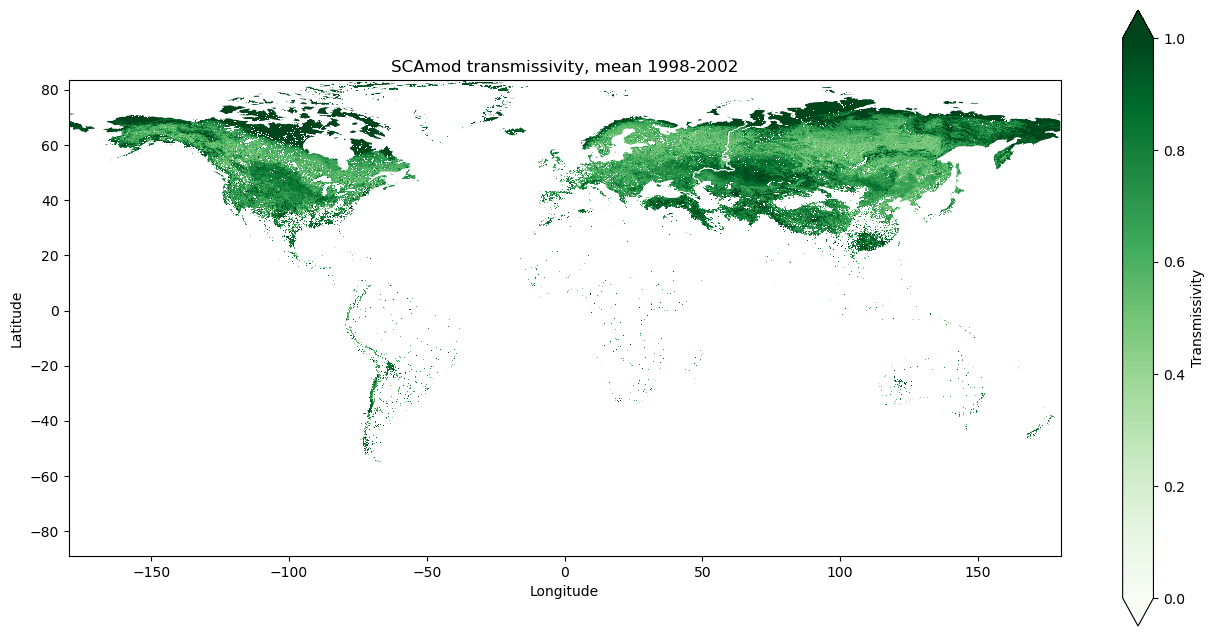

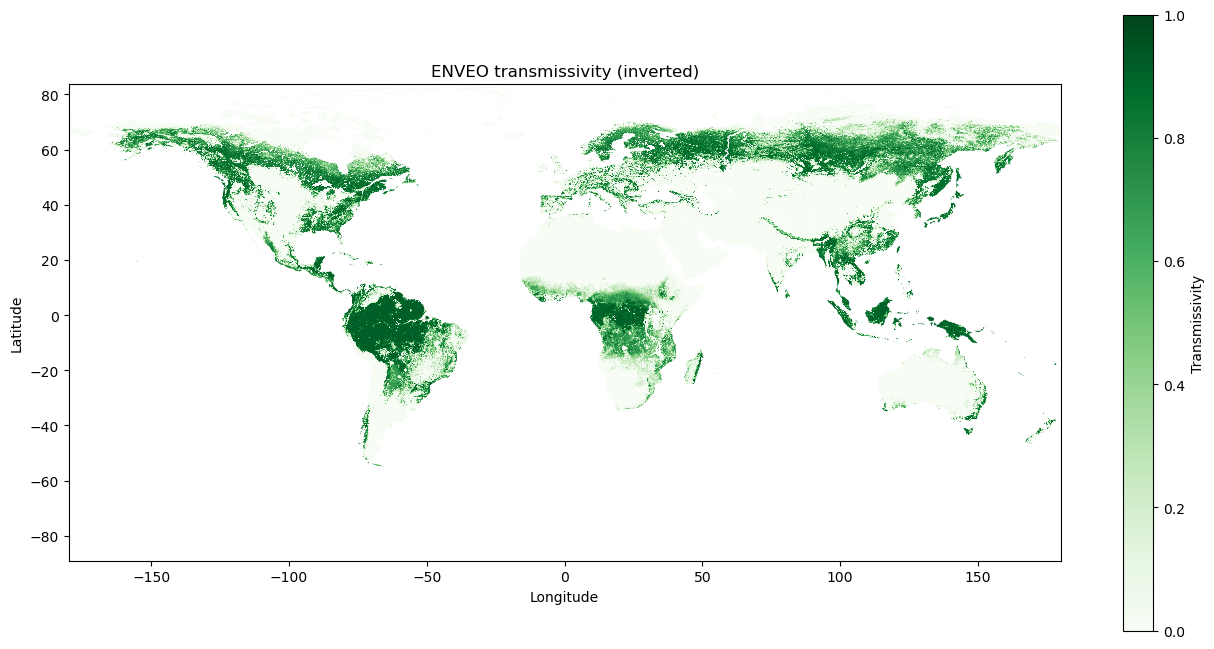

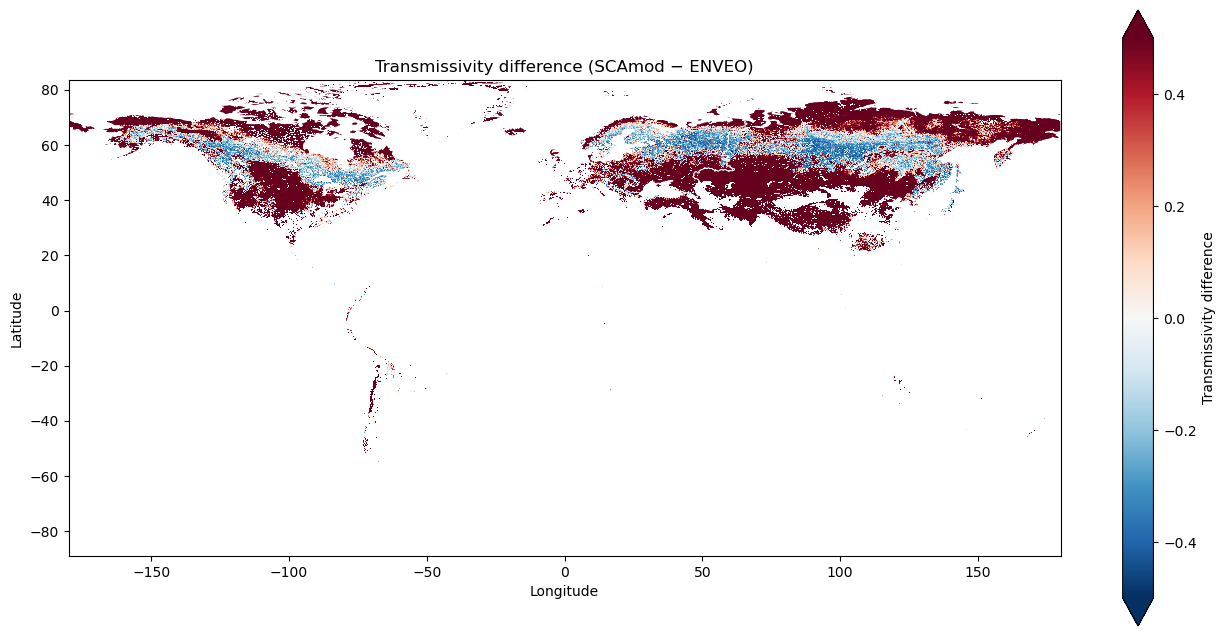

Mean difference: 0.473
RMSE:            0.667


In [79]:
import os
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box

os.makedirs("Figures", exist_ok=True)

# ---------------------------------------------------------------
# Assumes these already exist in your session:
#   ds_t2, ENVEO, ENVEO_ice, ENVEO_water, Map (GeoDataFrame)
# ---------------------------------------------------------------

# ---------- Data preparation ----------
Map = Map.to_crs(epsg=4326)

# SCAmod: mean over all years -> 2D map
t2 = ds_t2["__xarray_dataarray_variable__"]
t2_mean = t2.mean(dim="year", skipna=True)

# ENVEO: mask ice / water pixels
combined_mask = (ENVEO_ice == 0) | (ENVEO_water == 0)
ENVEO_masked = ENVEO.where(~combined_mask)

# Invert ENVEO (1 - value) so it follows the same convention as SCAmod
ENVEO_masked = 1 - ENVEO_masked

# Put SCAmod on the ENVEO grid so the two can be subtracted.
# NOTE: both arrays must use the same coordinate names (e.g. "x"/"y" or
# "lon"/"lat"). If not, rename first, e.g.:
#   t2_mean = t2_mean.rename({"lon": "x", "lat": "y"})
scamod_on_enveo = t2_mean.interp_like(ENVEO_masked, method="linear")

# Comparison: SCAmod minus ENVEO (positive = SCAmod higher transmissivity)
diff = scamod_on_enveo - ENVEO_masked

# ---------- Shared helpers ----------
xmin, ymin, xmax, ymax = Map.total_bounds
background = gpd.GeoDataFrame(geometry=[box(xmin, ymin, xmax, ymax)], crs="EPSG:4326")
outside = gpd.overlay(background, Map[["geometry"]], how="difference")


def make_cmap(name):
    cmap = plt.get_cmap(name).copy()
    cmap.set_bad(color="white")  # NaNs render white
    return cmap


def draw_map(da, title, cmap, vmin, vmax, cbar_label, outfile):
    fig, ax = plt.subplots(figsize=(16, 8))

    da.plot(
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        cbar_kwargs={"label": cbar_label},
    )

    # White-out everything outside the Map outline, then draw the outline
    outside.plot(ax=ax, color="white", edgecolor="none")
    Map.plot(ax=ax, facecolor="none", edgecolor="white", linewidth=0.5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title)

    fig.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()


# ---------- Map 1: SCAmod ----------
draw_map(
    t2_mean,
    "SCAmod transmissivity, mean 1998-2002",
    make_cmap("Greens"),     # same colormap as ENVEO so they are comparable
    0, 1,
    "Transmissivity",
    "Figures/SCAmod_transmissivity_mean_1998_2002.png",
)

# ---------- Map 2: ENVEO ----------
draw_map(
    ENVEO_masked,
    "ENVEO transmissivity (inverted)",
    make_cmap("Greens"),
    0, 1,
    "Transmissivity",
    "Figures/enveo_transmissivity.png",
)

# ---------- Map 3: Comparison (SCAmod - ENVEO) ----------
draw_map(
    diff,
    "Transmissivity difference (SCAmod \u2212 ENVEO)",
    make_cmap("RdBu_r"),     # diverging, centred on 0
    -0.5, 0.5,
    "Transmissivity difference",
    "Figures/transmissivity_difference_SCAmod_minus_ENVEO.png",
)

# Optional summary statistics for the comparison
print(f"Mean difference: {float(diff.mean(skipna=True)):.3f}")
print(f"RMSE:            {float((diff ** 2).mean(skipna=True) ** 0.5):.3f}")

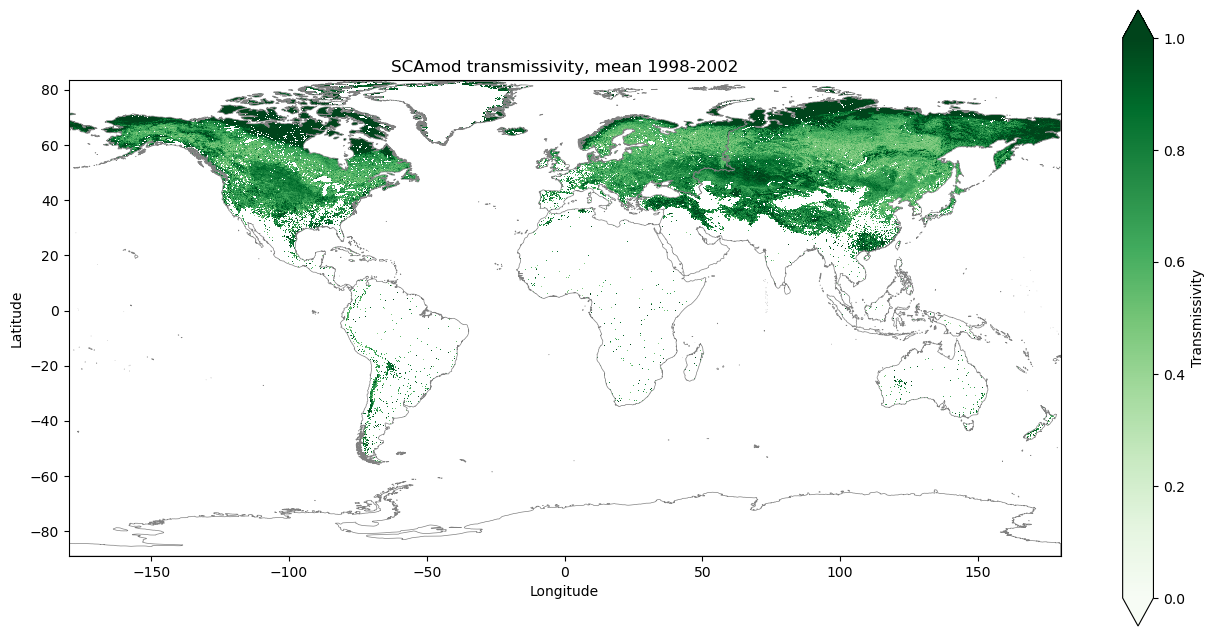

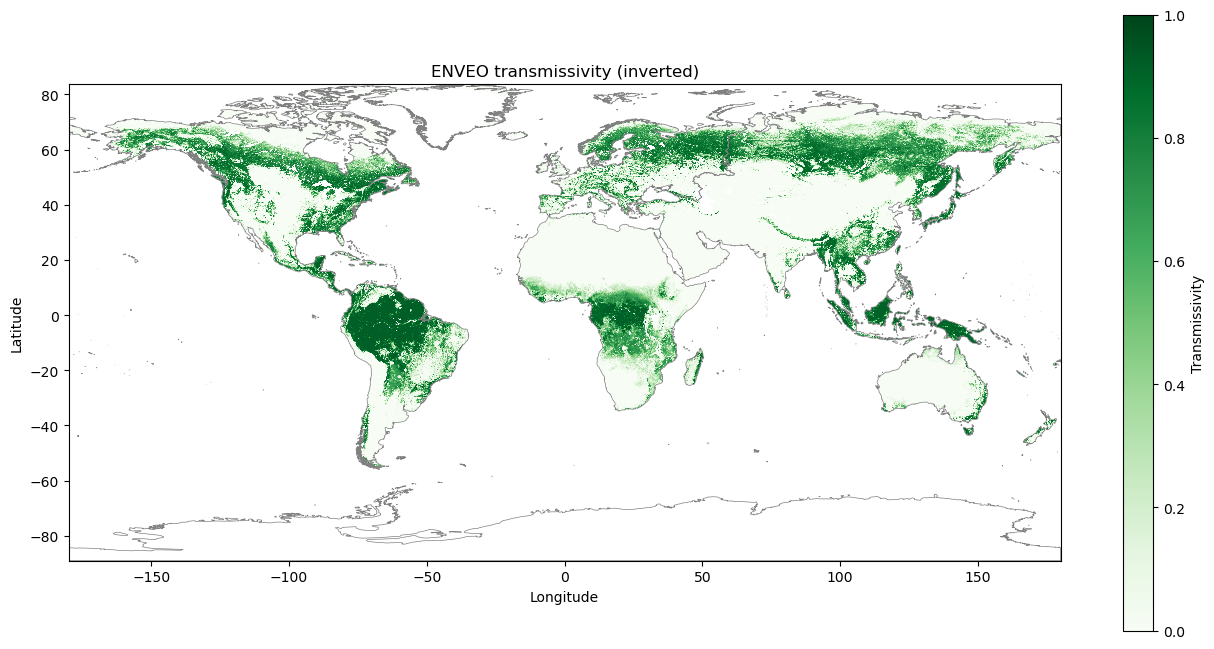

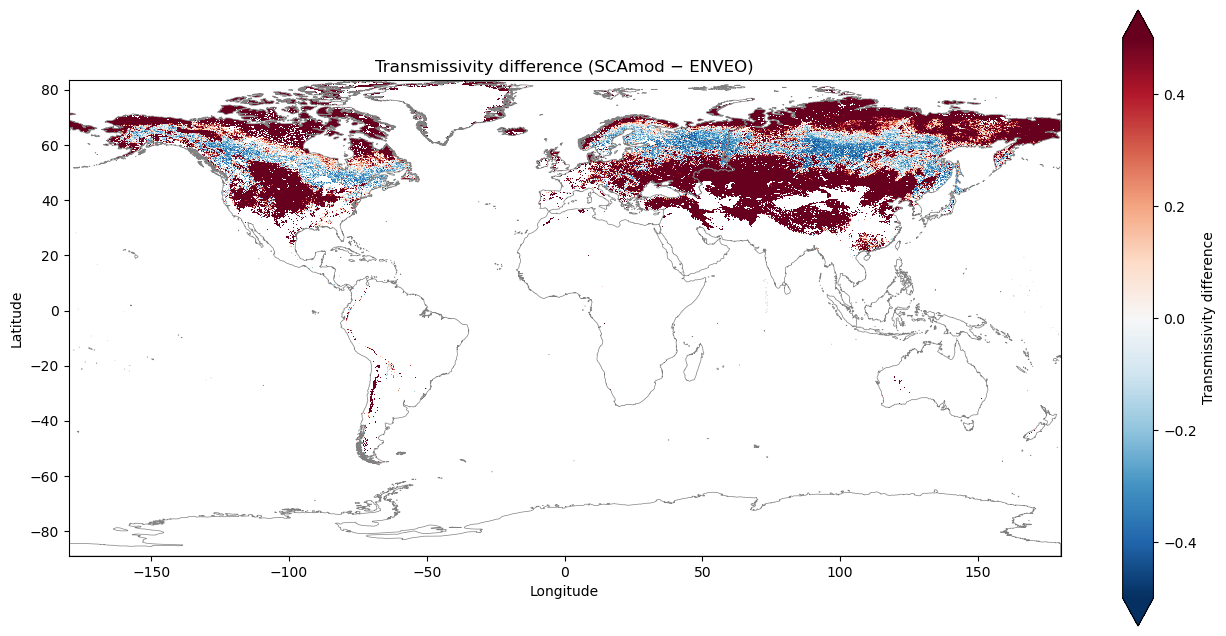

Mean difference: 0.473
RMSE:            0.667


In [103]:
import os
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box

os.makedirs("Figures", exist_ok=True)

# ---------------------------------------------------------------
# Assumes these already exist in your session:
#   ds_t2, ENVEO, ENVEO_ice, ENVEO_water, Map (GeoDataFrame)
# ---------------------------------------------------------------

# ---------- Data preparation ----------
Map = Map.to_crs(epsg=4326)

# SCAmod: mean over all years -> 2D map
t2 = ds_t2["__xarray_dataarray_variable__"]
t2_mean = t2.mean(dim="year", skipna=True)

# ENVEO: mask ice / water pixels
combined_mask = (ENVEO_ice == 0) | (ENVEO_water == 0)
ENVEO_masked = ENVEO.where(~combined_mask)

# Invert ENVEO (1 - value) so it follows the same convention as SCAmod
ENVEO_masked = 1 - ENVEO_masked

# Put SCAmod on the ENVEO grid so the two can be subtracted.
# NOTE: both arrays must use the same coordinate names (e.g. "x"/"y" or
# "lon"/"lat"). If not, rename first, e.g.:
#   t2_mean = t2_mean.rename({"lon": "x", "lat": "y"})
scamod_on_enveo = t2_mean.interp_like(ENVEO_masked, method="linear")

# Comparison: SCAmod minus ENVEO (positive = SCAmod higher transmissivity)
diff = scamod_on_enveo - ENVEO_masked

# ---------- Shared helpers ----------
xmin, ymin, xmax, ymax = Map.total_bounds
background = gpd.GeoDataFrame(geometry=[box(xmin, ymin, xmax, ymax)], crs="EPSG:4326")
outside = gpd.overlay(background, Map[["geometry"]], how="difference")


def make_cmap(name):
    cmap = plt.get_cmap(name).copy()
    cmap.set_bad(color="white")  # NaNs render white
    return cmap


def draw_map(da, title, cmap, vmin, vmax, cbar_label, outfile):
    fig, ax = plt.subplots(figsize=(16, 8))

    da.plot(
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        cbar_kwargs={"label": cbar_label},
    )

    # White-out everything outside the Map outline, then draw the outline
    outside.plot(ax=ax, color="white", edgecolor="none")
    Map.plot(ax=ax, facecolor="none", edgecolor="grey", linewidth=0.5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title)

    fig.savefig(outfile, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()


# ---------- Map 1: SCAmod ----------
draw_map(
    t2_mean,
    "SCAmod transmissivity, mean 1998-2002",
    make_cmap("Greens"),     # same colormap as ENVEO so they are comparable
    0, 1,
    "Transmissivity",
    "Figures/SCAmod_transmissivity_mean_1998_2002.png",
)

# ---------- Map 2: ENVEO ----------
draw_map(
    ENVEO_masked,
    "ENVEO transmissivity (inverted)",
    make_cmap("Greens"),
    0, 1,
    "Transmissivity",
    "Figures/enveo_transmissivity.png",
)

# ---------- Map 3: Comparison (SCAmod - ENVEO) ----------
draw_map(
    diff,
    "Transmissivity difference (SCAmod \u2212 ENVEO)",
    make_cmap("RdBu_r"),     # diverging, centred on 0
    -0.5, 0.5,
    "Transmissivity difference",
    "Figures/transmissivity_difference_SCAmod_minus_ENVEO.png",
)

# Optional summary statistics for the comparison
print(f"Mean difference: {float(diff.mean(skipna=True)):.3f}")
print(f"RMSE:            {float((diff ** 2).mean(skipna=True) ** 0.5):.3f}")

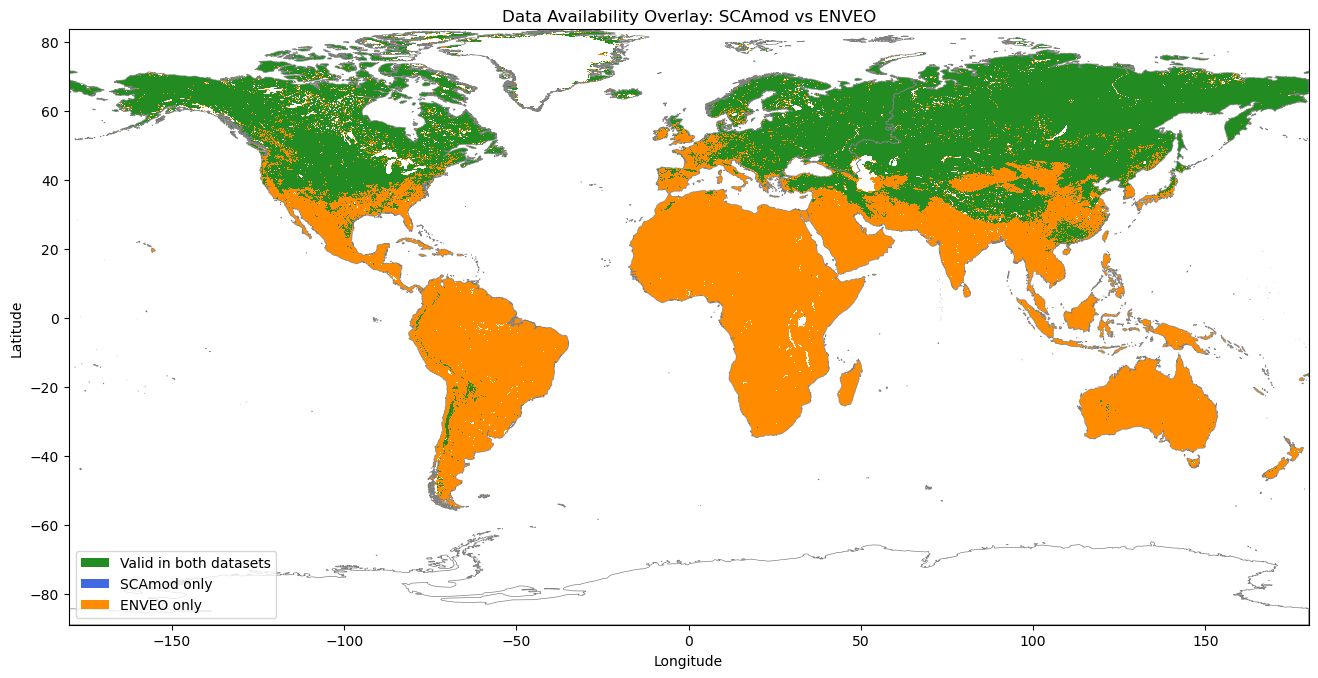

In [104]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import geopandas as gpd
from shapely.geometry import box

os.makedirs("Figures", exist_ok=True)

# Ensure the study-area boundaries use longitude/latitude
Map = Map.to_crs(epsg=4326)

# Check valid data in each dataset on the same grid
valid_scamod = scamod_on_enveo.notnull()
valid_enveo = ENVEO_masked.notnull()

# Encode data availability:
# 0 = neither valid
# 1 = valid in both
# 2 = SCAmod only
# 3 = ENVEO only
availability = (
    valid_scamod.astype("int8")
    + 2 * valid_enveo.astype("int8")
)

# Map the combinations to the desired categories:
# both = 3, SCAmod only = 1, ENVEO only = 2, neither = 0
availability = availability.where(availability != 0)

# Plot extent based on the study area
xmin, ymin, xmax, ymax = Map.total_bounds

# White out the area outside the study-area polygons
background = gpd.GeoDataFrame(
    geometry=[box(xmin, ymin, xmax, ymax)],
    crs="EPSG:4326"
)
outside = gpd.overlay(background, Map[["geometry"]], how="difference")

# Colors for categories 1, 2, 3 in the encoded array
# SCAmod only = blue, ENVEO only = orange, both = green
cmap = ListedColormap(["royalblue", "darkorange", "forestgreen"])
plot_data = availability.where(availability.notnull()) - 1

fig, ax = plt.subplots(figsize=(16, 8))

plot_data.plot(
    ax=ax,
    cmap=cmap,
    vmin=0,
    vmax=2,
    add_colorbar=False
)

# Mask outside the study area and add boundary outlines
outside.plot(ax=ax, color="white", edgecolor="none")
Map.plot(ax=ax, facecolor="none", edgecolor="grey", linewidth=0.5)

# Legend
from matplotlib.patches import Patch

legend_items = [
    Patch(facecolor="forestgreen", label="Valid in both datasets"),
    Patch(facecolor="royalblue", label="SCAmod only"),
    Patch(facecolor="darkorange", label="ENVEO only"),
]

ax.legend(handles=legend_items, loc="lower left", frameon=True)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Data Availability Overlay: SCAmod vs ENVEO")

fig.savefig(
    "Figures/data_availability_overlay.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()